# 02 - Exploração supervisionada (somente treino)

Terceira etapa do pipeline (`acquire -> eda -> prepare -> explore -> train`).

Este notebook calcula as **relações entre features e alvo** que orientam a modelagem, e o faz
**apenas sobre o split de treino** (`data/processed/train.csv`). O EDA estrutural
([`01_eda.ipynb`](01_eda.ipynb)) não toca o alvo além da contagem marginal.

**Por que a restrição:** a execução histórica do EDA calculou essas relações nas 30.000
linhas do bruto, incluindo as linhas que depois seriam atribuídas ao conjunto de teste. A
exposição está declarada em [`docs/evidence/fase-1.md`](../docs/evidence/fase-1.md) e o
artefato histórico contaminante foi preservado em `reports/eda/history/`. A partir daqui, a
exploração que guia decisões de modelagem é restrita ao treino.

A lógica vive em `src/credit_monitoring/explore.py`; o mesmo código roda no estágio `explore`
do `dvc.yaml`. Aqui as saídas vão para uma pasta temporária para não alterar as saídas
rastreadas pelo DVC.

In [1]:
import json
import tempfile
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from credit_monitoring.config import load_config
from credit_monitoring.explore import run_exploration
from credit_monitoring.paths import PROCESSED_DATA_DIR

pd.options.display.float_format = "{:,.3f}".format

config = load_config()
target = config["dataset"]["canonical_target"]
train_csv = PROCESSED_DATA_DIR / "train.csv"

output_dir = Path(tempfile.mkdtemp(prefix="explore_"))
summary = run_exploration(
    train_csv,
    config,
    figures_dir=output_dir / "figures",
    summary_path=output_dir / "train_exploration.json",
)


def show(name):
    display(Image(filename=output_dir / "figures" / name))

## 1. Correlação com o alvo (treino)

`PAY_0` é a variável mais correlacionada com o alvo; atrasos recentes pesam mais que
antigos. `LIMIT_BAL` tem correlação negativa.

,pearson
PAY_0,0.327
PAY_2,0.268
PAY_3,0.241
PAY_4,0.223
PAY_5,0.208
PAY_6,0.194
LIMIT_BAL,-0.159
PAY_AMT1,-0.070
PAY_AMT2,-0.067
PAY_AMT4,-0.056


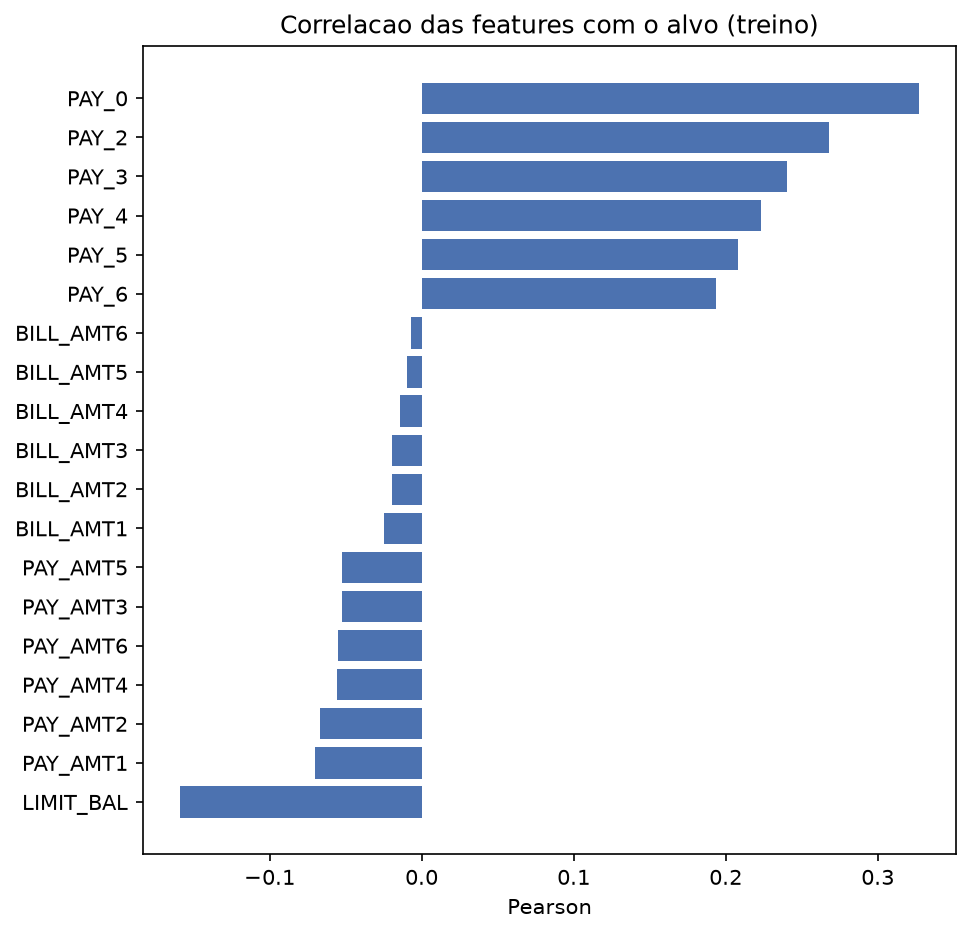

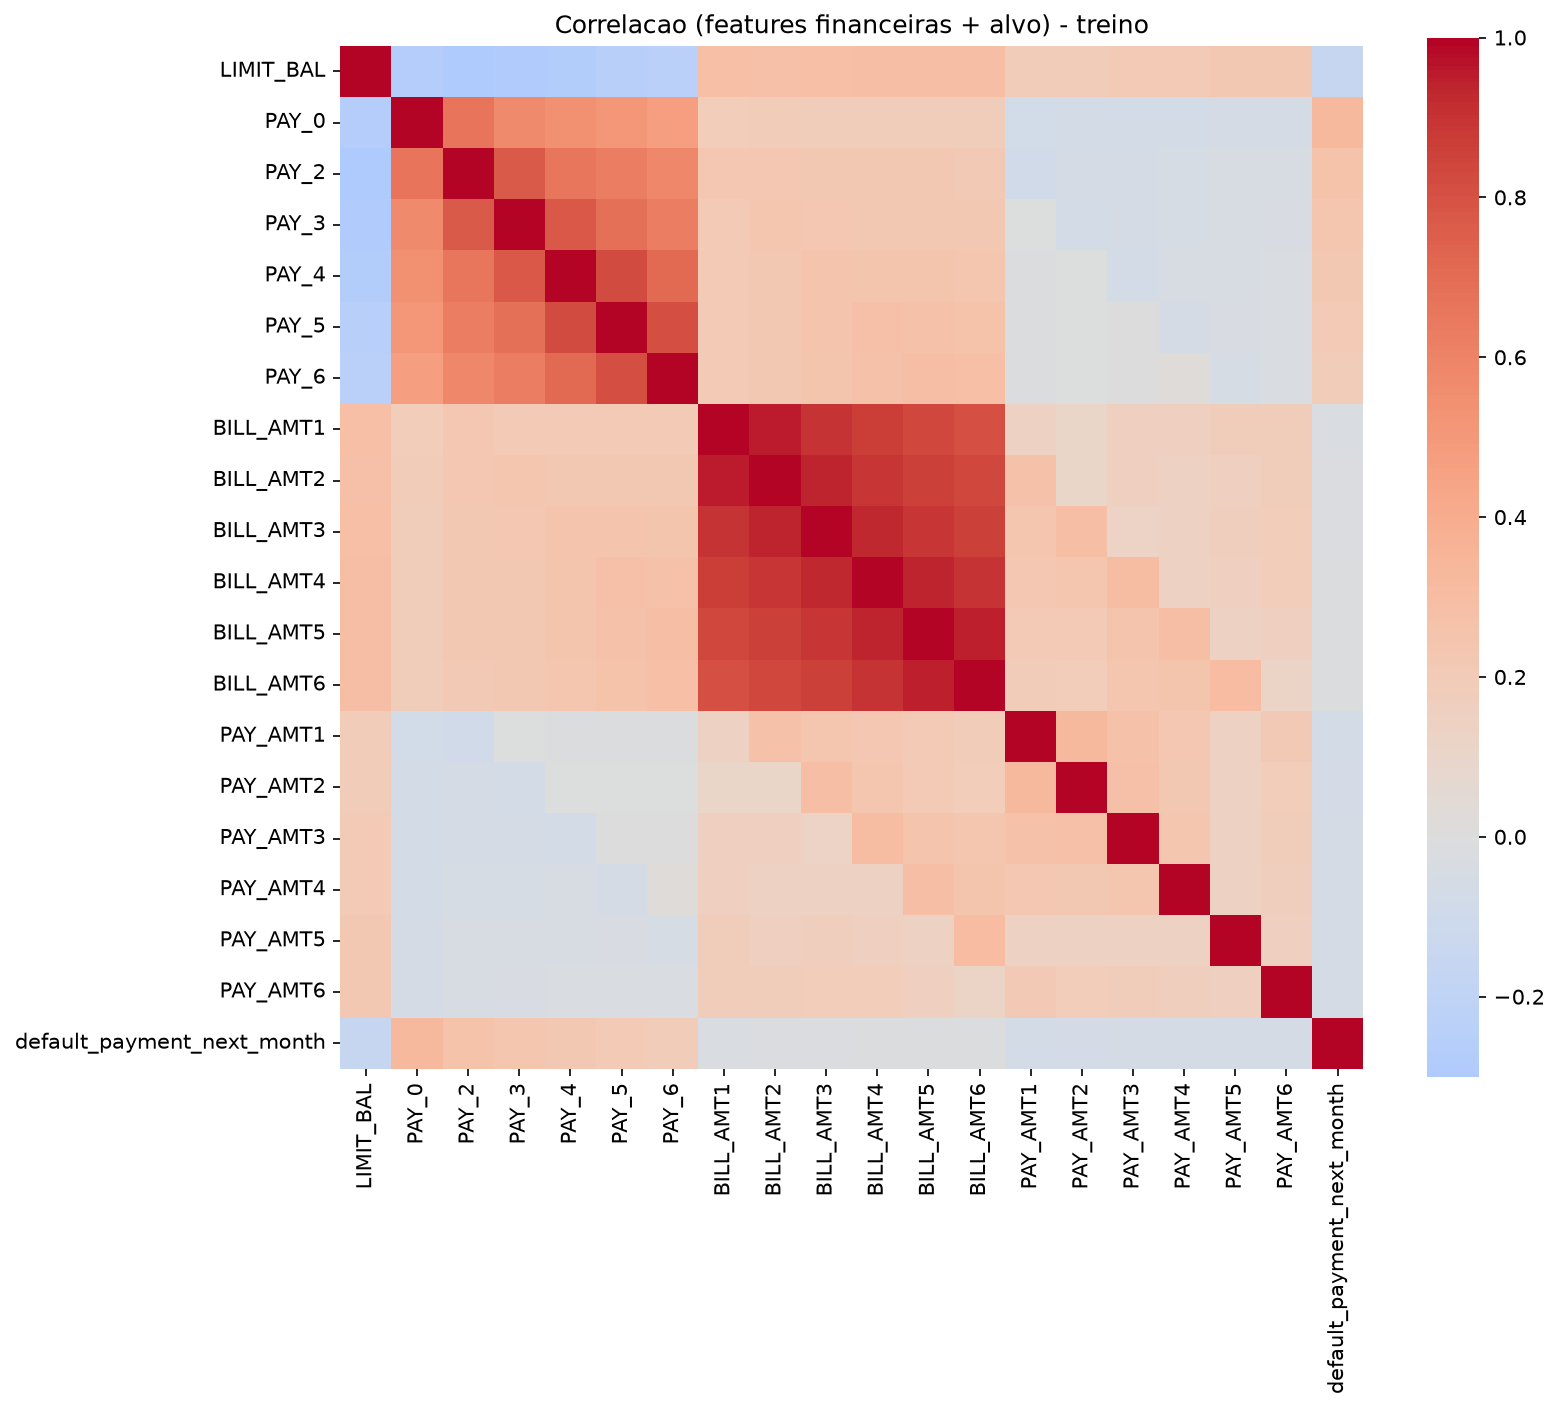

In [2]:
display(pd.Series(summary["top_target_correlations"], name="pearson").sort_values(key=abs, ascending=False).to_frame())
show("01_target_correlation.png")
show("02_correlation_heatmap.png")

## 2. Taxa de default por grupo demográfico (treino)

`SEX`, `EDUCATION`, `MARRIAGE` e `AGE` ficam **fora** do modelo (auditoria de viés na
governança). As taxas abaixo são observadas para documentar possíveis disparidades, sempre
com os respectivos denominadores.

{
  "SEX": {
    "1": {
      "default_rate": 0.243003,
      "rows": 8325
    },
    "2": {
      "default_rate": 0.206864,
      "rows": 12675
    }
  },
  "EDUCATION": {
    "0": {
      "default_rate": 0.0,
      "rows": 12
    },
    "1": {
      "default_rate": 0.194742,
      "rows": 7379
    },
    "2": {
      "default_rate": 0.23594,
      "rows": 9833
    },
    "3": {
      "default_rate": 0.250872,
      "rows": 3440
    },
    "4": {
      "default_rate": 0.056818,
      "rows": 88
    },
    "5": {
      "default_rate": 0.066351,
      "rows": 211
    },
    "6": {
      "default_rate": 0.162162,
      "rows": 37
    }
  },
  "MARRIAGE": {
    "0": {
      "default_rate": 0.1,
      "rows": 40
    },
    "1": {
      "default_rate": 0.232836,
      "rows": 9526
    },
    "2": {
      "default_rate": 0.210385,
      "rows": 11208
    },
    "3": {
      "default_rate": 0.287611,
      "rows": 226
    }
  }
}
{
  "(17, 25]": {
    "default_rate": 0.269642,
    "rows": 271

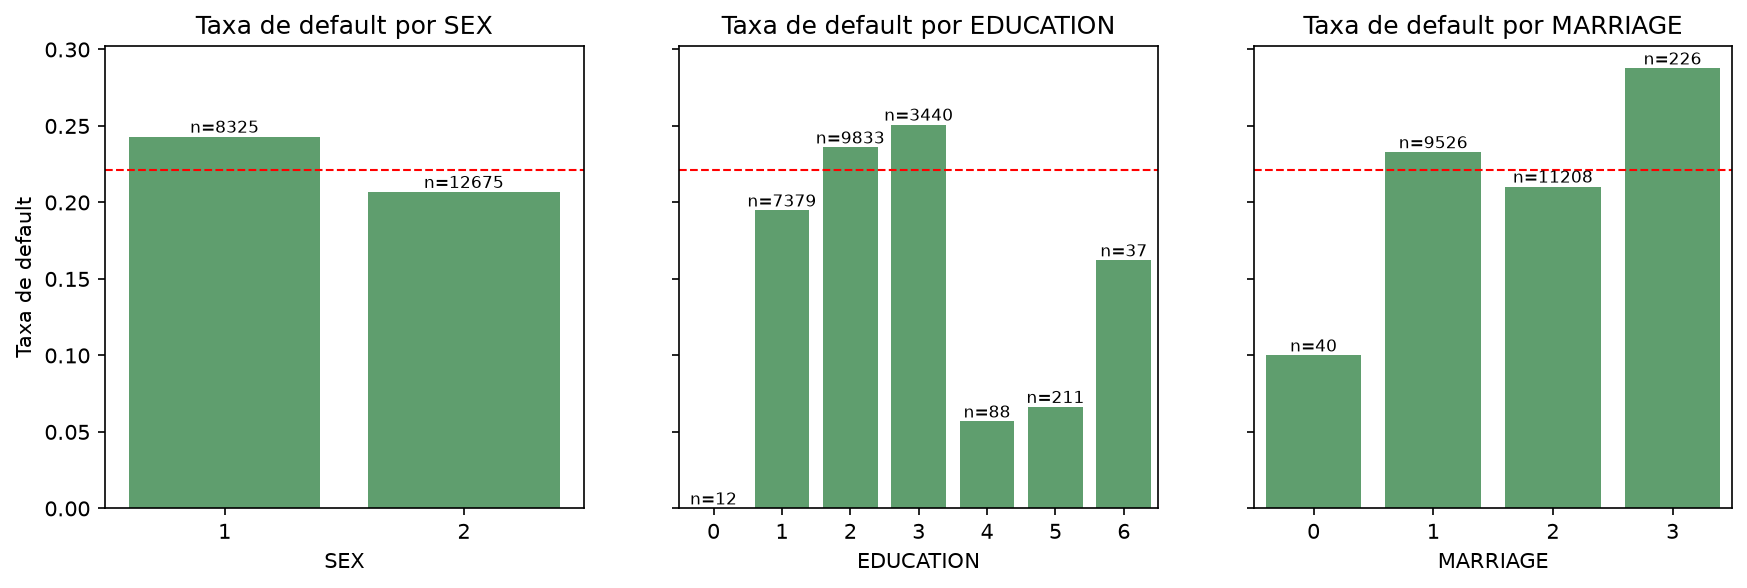

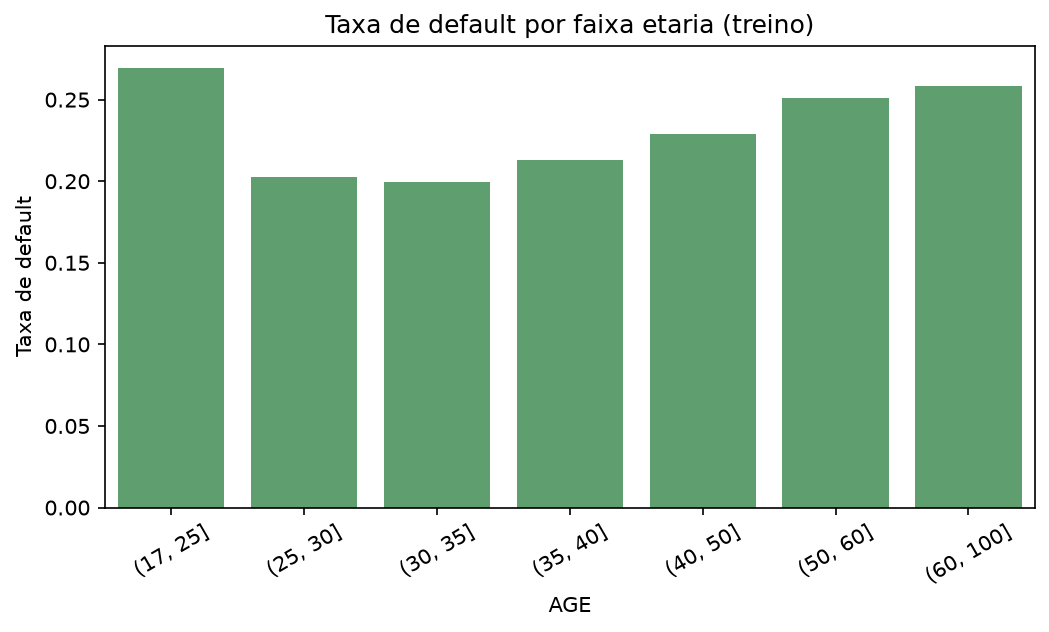

In [3]:
print(json.dumps(summary["default_rate_by_group"], indent=2))
print(json.dumps(summary["default_rate_by_age_band"], indent=2))
show("03_categorical_default_rate.png")
show("04_age_default_rate.png")

## 3. Status de pagamento e limite de crédito (treino)

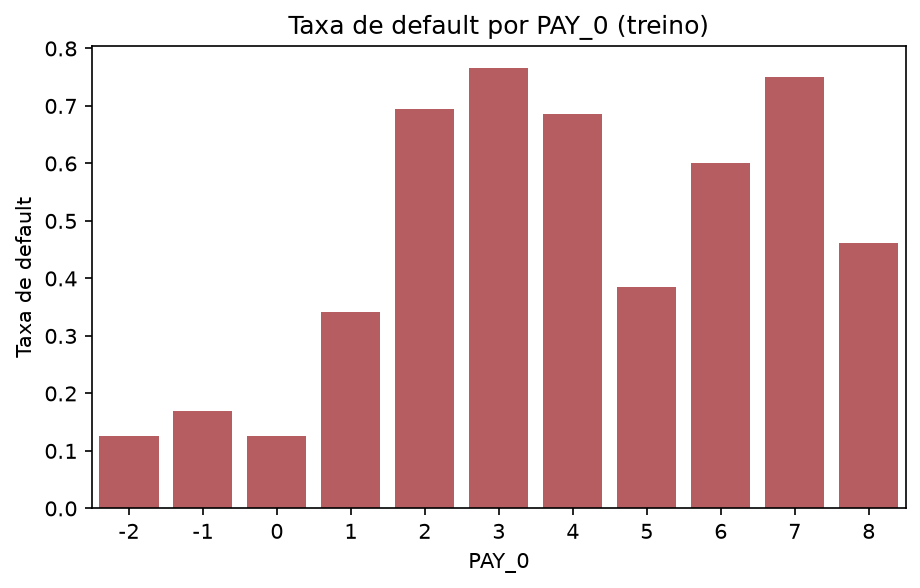

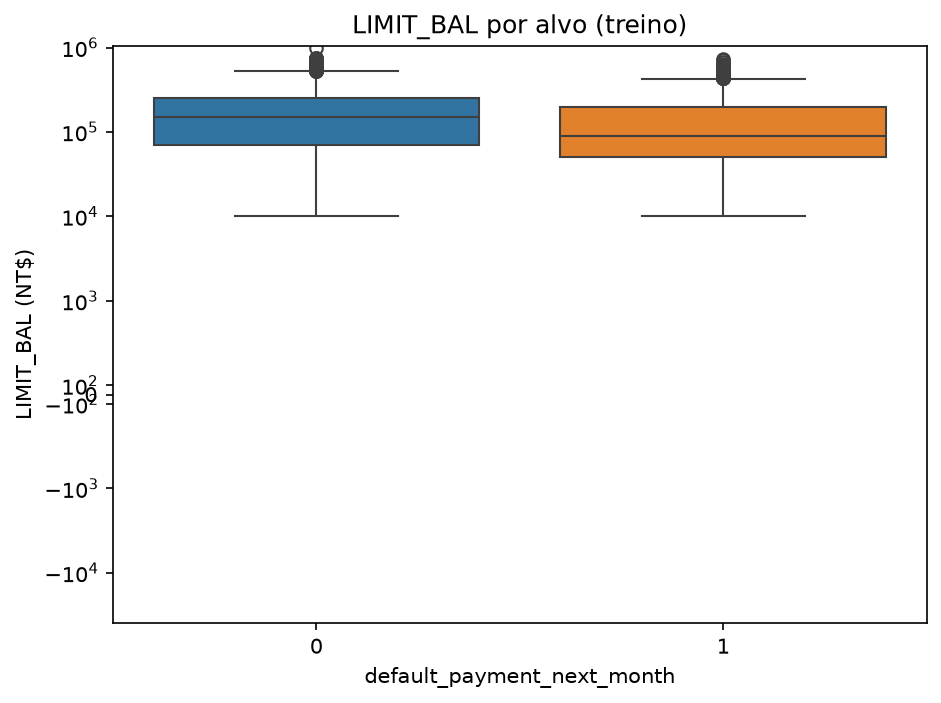

In [4]:
show("05_payment_status_default_rate.png")
show("06_limit_bal_by_target.png")

## 4. Decisões registradas

- Remoção apenas de linhas estruturalmente inválidas (nulos, `ID` duplicado, alvo fora de
  {0,1}, `LIMIT_BAL` <= 0, idade fora de 18-100); nenhuma recodificação e nenhuma remoção de
  outliers.
- Split estratificado 70/15/15 pelo alvo, seed 42.
- Desbalanceamento tratado com `class_weight` nos modelos; seleção por ROC-AUC na validação.
- `SEX`, `EDUCATION`, `MARRIAGE` e `AGE` fora do modelo; entram as 19 features financeiras.
- A Regressão Logística usa `StandardScaler` por causa da escala e da cauda longa dos valores
  monetários; o Random Forest dispensa escala.